# 7 — Mise en classe du score (CHR) · Segment : Comptes joints

Chapitre 7 du cours : transformer le score en points (grille PDO du notebook `6`) en un nombre restreint de
**Classes Homogènes de Risque (CHR)**, dernière étape de la *risk differentiation* avant le calibrage (ch. 8).

| Étape | Question | Section |
|-------|----------|---------|
| 7.1 | Comment construire le découpage : découpage fin puis fusion de classes adjacentes ? | Construction |
| 7.2 | Les CHR sont-elles stables en risque et en volume dans le temps ? | Stabilité |
| 7.3 | Une variable exogène révèle-t-elle des sous-populations de risque différent dans une CHR ? | Homogénéité |
| 7.4 | Deux CHR adjacentes sont-elles assez différentes (écart relatif ≥ 30 %) ? | Hétérogénéité |
| 7.5 | Faut-il une échelle maître ? | Échelle maître |
| 7.6 | Quelle part du pouvoir discriminant la mise en classe fait-elle perdre ? | Perte d'information |

> Convention : **CHR 1 = la moins risquée**, CHR K = la plus risquée. Les bornes sont apprises sur l'**apprentissage**
> seul, puis appliquées au test (et plus tard à l'OOT) sans être modifiées.

## 0. Imports et configuration

In [1]:
import sys, json
from pathlib import Path

# Racine du projet : ce notebook est rangé dans Segmentation_joint/
ROOT = Path.cwd().parent if Path.cwd().name == "Segmentation_joint" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from utils.modele import appliquer_fusions
from utils.scorecard import noter
from utils.binning import stabilite_decoupages, plot_stabilite
from utils.chr import (
    construire_chr, affecter_chr, libelles_chr, table_chr, homogeneite_exogene, binariser_mediane,
    perte_information, plot_chr, plot_bornes_score, chr_optbinning, comparer_decoupages,
)
from utils.exploration import exporter_excel

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(16)

polars.config.Config

### Paramètres

In [2]:
VERSION = ""     # "" : modèle de référence (5 / 6) ; "_v2" : variante (5_v2 / 6_v2)

BASE_CL  = ROOT.parent / "data/segments/joint/base_joint_classes.parquet"   # variables en classes (sortie de 4)
BASE_ORI = ROOT.parent / "data/segments/joint/base_joint.parquet"           # base du segment, pour les variables exogènes
GRILLE   = ROOT / f"outputs/scorecard/grille_joint{VERSION}.json"
SORTIE   = ROOT / f"outputs/chr/chr_joint{VERSION}.json"
SORTIE_XLS = ROOT / f"outputs/chr/chr_joint{VERSION}.xlsx"

TARGET   = "ddefaut_ndb"
ID_COL   = "gdt"
DATE_COL = "datdelhis"
COHORTE  = "1mo"            # cohortes mensuelles, comme au ch. 4

# Règles de construction des CHR (cours 7.1 à 7.4)
N_FIN       = 20            # découpage fin : 20 quantiles du score
SEUIL       = 0.30          # écart relatif minimal de taux de défaut entre CHR adjacentes
MIN_DEFAUTS = 5             # défauts minimum par CHR (en apprentissage)
MIN_PART    = 0.02          # effectif minimum par CHR (2 % de l'apprentissage)
ALPHA       = 0.05
SEUIL_PSI   = 0.10

# Variables exogènes au score (cours 7.3.1) : non testées dans le modèle
EXOGENES = ["age", "age_ans", "nb_tiers", "code_marche_v2", "type_PM_PP"]

## 1. Chargement : score en points de chaque dossier

In [3]:
g = json.loads(GRILLE.read_text(encoding="utf-8"))
VARS = g["variables"]
FUSIONS = {v: {int(a): b for a, b in f.items()} for v, f in g["fusions"].items()}
grille = pl.DataFrame(g["grille_pdo"])

df = appliquer_fusions(pl.read_parquet(BASE_CL), FUSIONS)
df = noter(df, grille, "points").with_columns(cohorte=pl.col(DATE_COL).dt.truncate(COHORTE).dt.to_string("%Y-%m"))
df_app  = df.filter(pl.col("echantillon") == "apprentissage")
df_test = df.filter(pl.col("echantillon") == "test")

print(f"Grille PDO de {len(VARS)} variables ({GRILLE.name}) | "
      f"apprentissage : {df_app.height} dossiers, {int(df_app[TARGET].sum())} défauts | "
      f"test : {df_test.height} dossiers, {int(df_test[TARGET].sum())} défauts")
print(f"{df_app['points'].n_unique()} valeurs de score distinctes en apprentissage "
      f"(de {df_app['points'].min():.0f} à {df_app['points'].max():.0f} points)")

Grille PDO de 5 variables (grille_joint.json) | apprentissage : 47156 dossiers, 228 défauts | test : 11791 dossiers, 56 défauts
91 valeurs de score distinctes en apprentissage (de 540 à 725 points)


## 7.1 Construction des CHR

### 7.1.2 Le score d'une grille n'est pas continu

Le score est la somme des points des modalités : il ne prend qu'un nombre fini de valeurs (au plus le produit des
nombres de classes des variables), d'où des **paliers**. Une borne placée au milieu d'un palier séparerait deux
dossiers de score identique : les bornes sont donc toujours prises **entre deux valeurs observées** du score.

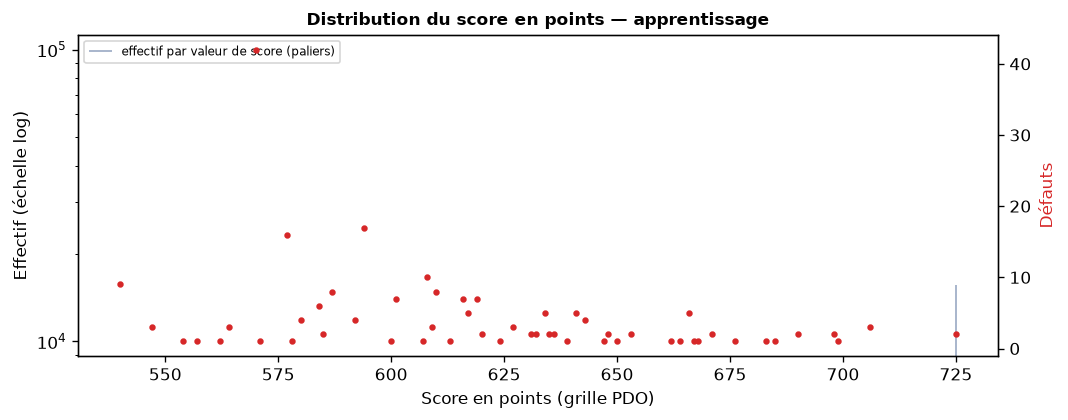

In [4]:
fig = plot_bornes_score(df_app["points"], df_app[TARGET], [], titre="Distribution du score en points — apprentissage")
plt.show()

### 7.1.3 Découpage fin puis fusion

Découpage fin en 20 quantiles du score (bornes sur les valeurs observées), puis fusions successives de **deux classes
adjacentes**, une à la fois, par ordre de priorité :

1. classe trop petite (< 2 % des dossiers ou < 5 défauts) → elle rejoint sa voisine de taux le plus proche ;
2. rupture de monotonie (une classe moins bien notée n'est pas plus risquée) ;
3. écart relatif de taux de défaut avec la voisine **< 30 %** (7.2.1 / 7.4).

Deux variantes de la règle 3 sont comparées :

- **ponctuelle** : $R_k = \tau_k / \tau_{k-1} - 1 \geq 30\,\%$ ;
- **avec IC** (cours 7.2.1, « pour aller plus loin ») : la borne basse de l'IC à 95 % de $R_k$, par la méthode delta,
  doit rester ≥ 30 %. Plus exigeante, elle tient compte du faible nombre de défauts.

In [5]:
resultats = {}
for critere in ("ponctuel", "ic"):
    bornes, journal = construire_chr(df_app["points"], df_app[TARGET], n_fin=N_FIN, seuil=SEUIL, critere=critere,
                                     min_defauts=MIN_DEFAUTS, min_part=MIN_PART, alpha=ALPHA)
    d = df_app.with_columns(CHR=pl.Series(affecter_chr(df_app["points"], bornes)))
    resultats[critere] = (bornes, journal, table_chr(d, "CHR", TARGET, SEUIL, ALPHA, points="points"))
    print(f"critère {critere:9s} : {len(bornes) + 1} CHR | bornes = {bornes} | {journal.height} fusions")

critère ponctuel  : 6 CHR | bornes = [594.0, 615.0, 632.0, 641.0, 671.0] | 7 fusions
critère ic        : 4 CHR | bornes = [594.0, 632.0, 671.0] | 9 fusions


In [6]:
for critere, (bornes, journal, t) in resultats.items():
    print(f"=== critère {critere}")
    display(t.with_columns(libelle=pl.col("CHR").replace_strict(libelles_chr(bornes)))
             .select("CHR", "libelle", "n", "part", "n_defaut", "taux_defaut", "R", "R_ic_bas", "R_ic_haut",
                     "ecart_ok", "ecart_ic_ok"))

=== critère ponctuel


CHR,libelle,n,part,n_defaut,taux_defaut,R,R_ic_bas,R_ic_haut,ecart_ok,ecart_ic_ok
i64,str,u32,f64,f64,f64,f64,f64,f64,bool,bool
1,"""> 671""",30064,0.637543,13.0,0.000432,null,null,null,null,null
2,"""]641 ; 671]""",7560,0.160319,21.0,0.002778,5.423932,0.98357,9.864293,true,true
3,"""]632 ; 641]""",2321,0.04922,15.0,0.006463,1.326583,-0.211182,2.864349,true,false
4,"""]615 ; 632]""",2487,0.05274,29.0,0.011661,0.804289,-0.315769,1.924347,true,false
5,"""]594 ; 615]""",2042,0.043303,31.0,0.015181,0.301918,-0.352878,0.956715,true,false
6,"""≤ 594""",2682,0.056875,119.0,0.04437,1.922686,0.779899,3.065474,true,true


=== critère ic


CHR,libelle,n,part,n_defaut,taux_defaut,R,R_ic_bas,R_ic_haut,ecart_ok,ecart_ic_ok
i64,str,u32,f64,f64,f64,f64,f64,f64,bool,bool
1,"""> 671""",30064,0.637543,13.0,0.000432,null,null,null,null,null
2,"""]632 ; 671]""",9881,0.209539,36.0,0.003643,7.425681,2.085584,12.765778,true,true
3,"""]594 ; 632]""",4529,0.096043,60.0,0.013248,2.636196,1.139185,4.133208,true,true
4,"""≤ 594""",2682,0.056875,119.0,0.04437,2.349186,1.322209,3.376163,true,true


### Choix du découpage

Le critère retenu est fixé ci-dessous après lecture des deux tableaux (voir la lecture en fin de section).

In [7]:
CRITERE = "ic"
BORNES, JOURNAL, _ = resultats[CRITERE]
LIBELLES = libelles_chr(BORNES)
K = len(BORNES) + 1

df = df.with_columns(CHR=pl.Series(affecter_chr(df["points"], BORNES)))
df_app  = df.filter(pl.col("echantillon") == "apprentissage")
df_test = df.filter(pl.col("echantillon") == "test")

tab_app  = table_chr(df_app, "CHR", TARGET, SEUIL, ALPHA, points="points")
tab_test = table_chr(df_test, "CHR", TARGET, SEUIL, ALPHA, points="points")
print(f"Critère retenu : {CRITERE} → {K} CHR")
print("Journal des fusions :")
with pl.Config(tbl_rows=-1, fmt_str_lengths=60):
    display(JOURNAL)

Critère retenu : ic → 4 CHR
Journal des fusions :


n_classes_avant,motif,points_fusionnes,taux_a,taux_b
i64,str,str,f64,f64
13,"""effectif ou nombre de défauts insuffisant""","""]685 ; 702]""",0.001249,0.00235
12,"""effectif ou nombre de défauts insuffisant""","""]671 ; 685]""",0.00033,0.000469
11,"""effectif ou nombre de défauts insuffisant""","""]641 ; 660]""",0.001309,0.002876
10,"""effectif ou nombre de défauts insuffisant""","""]685 ; 706]""",0.000999,0.001538
9,"""effectif ou nombre de défauts insuffisant""","""]671 ; 706]""",0.001279,0.000366
8,"""effectif ou nombre de défauts insuffisant""","""]671 ; inf]""",0.000128,0.000761
7,"""rupture de monotonie""","""]641 ; 671]""",0.003881,0.002116
6,"""écart relatif < 30% (borne basse de l'IC)""","""]594 ; 632]""",0.011661,0.015181
5,"""écart relatif < 30% (borne basse de l'IC)""","""]632 ; 671]""",0.002778,0.006463


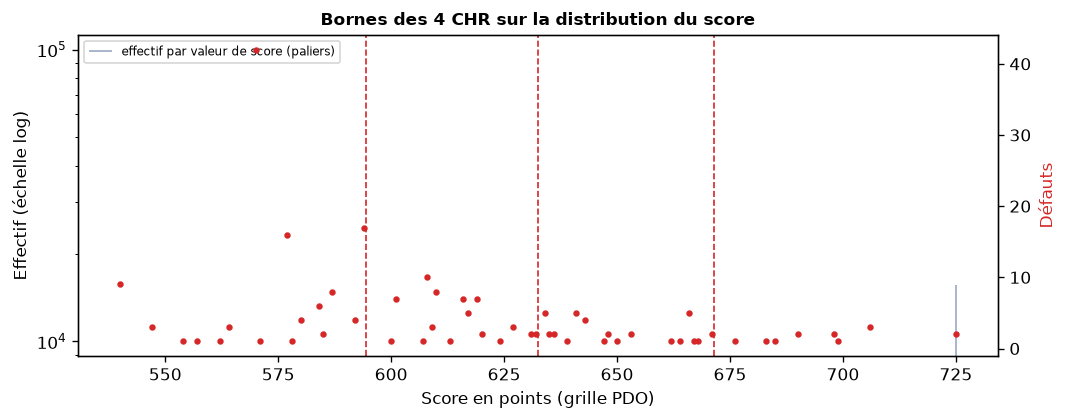

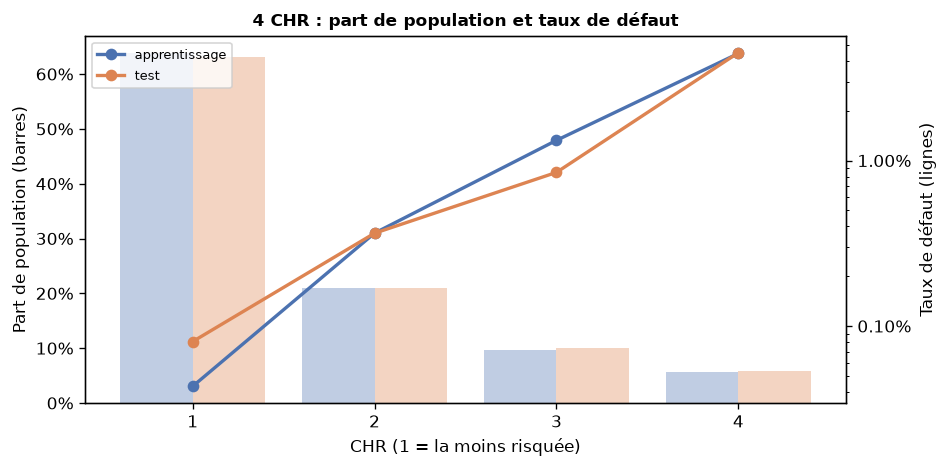

In [8]:
fig = plot_bornes_score(df_app["points"], df_app[TARGET], BORNES, titre=f"Bornes des {K} CHR sur la distribution du score")
plt.show()
fig = plot_chr({"apprentissage": tab_app, "test": tab_test}, titre=f"{K} CHR : part de population et taux de défaut")
plt.show()

In [9]:
pl.concat([
    tab_app.select(pl.lit("apprentissage").alias("echantillon"), "CHR", "n", "part", "n_defaut", "taux_defaut", "R"),
    tab_test.select(pl.lit("test").alias("echantillon"), "CHR", "n", "part", "n_defaut", "taux_defaut", "R"),
]).with_columns(libelle=pl.col("CHR").replace_strict(LIBELLES)).sort("CHR", "echantillon")

echantillon,CHR,n,part,n_defaut,taux_defaut,R,libelle
str,i64,u32,f64,f64,f64,f64,str
"""apprentissage""",1,30064,0.637543,13.0,0.000432,null,"""> 671"""
"""test""",1,7448,0.631668,6.0,0.000806,null,"""> 671"""
"""apprentissage""",2,9881,0.209539,36.0,0.003643,7.425681,"""]632 ; 671]"""
"""test""",2,2473,0.209736,9.0,0.003639,3.51759,"""]632 ; 671]"""
"""apprentissage""",3,4529,0.096043,60.0,0.013248,2.636196,"""]594 ; 632]"""
"""test""",3,1179,0.099992,10.0,0.008482,1.3306,"""]594 ; 632]"""
"""apprentissage""",4,2682,0.056875,119.0,0.04437,2.349186,"""≤ 594"""
"""test""",4,691,0.058604,31.0,0.044863,4.289291,"""≤ 594"""


## 7.2 Stabilité en risque et en volume dans le temps

Pour chaque cohorte mensuelle de l'apprentissage, puis entre apprentissage et test :

- **risque** : l'ordre $TD_{1,t} \leq \dots \leq TD_{K,t}$ doit tenir dans chaque cohorte, et l'écart relatif moyen
  entre CHR adjacentes doit rester ≥ 30 % ;
- **volume** : la part de chaque CHR doit rester stable (PSI ≤ 0,10, formalisé en 9.3).

Attention à ne pas confondre stabilité et stationnarité : un taux de défaut qui monte dans toutes les CHR à la fois
n'est pas une instabilité.

In [10]:
detail_coh, stab_coh = stabilite_decoupages(df_app, ["CHR"], TARGET, "cohorte", seuil_ecart=SEUIL, seuil_psi=SEUIL_PSI)
detail_ech, stab_ech = stabilite_decoupages(df, ["CHR"], TARGET, "echantillon", seuil_ecart=SEUIL, seuil_psi=SEUIL_PSI)
display(pl.concat([stab_coh.with_columns(groupe=pl.lit("cohortes de l'apprentissage")),
                   stab_ech.with_columns(groupe=pl.lit("apprentissage / test"))]).drop("variable"))
detail_coh.select("groupe", "classe", "n", "n_defaut", "part", "taux_defaut", "ecart_relatif").pivot(
    on="groupe", index="classe", values=["part", "taux_defaut"]).sort("classe")

ecart_moyen_min,part_groupes_ordonnes,psi_max,stable_risque,stable_volume,groupe
f64,f64,f64,bool,bool,str
2.403733,1.0,0.000256,true,true,"""cohortes de l'apprentissage"""
1.983398,1.0,0.000169,true,true,"""apprentissage / test"""


classe,part_2021-01,part_2021-02,part_2021-03,part_2021-04,taux_defaut_2021-01,taux_defaut_2021-02,taux_defaut_2021-03,taux_defaut_2021-04
i64,f64,f64,f64,f64,f64,f64,f64,f64
1,0.636488,0.635269,0.636133,0.642271,0.000402,0.000534,0.0,0.00079
2,0.210571,0.208902,0.214443,0.204247,0.004858,0.003653,0.001974,0.004143
3,0.097869,0.09521,0.093803,0.097301,0.015679,0.010686,0.013538,0.013043
4,0.055072,0.060619,0.055621,0.056181,0.040248,0.036364,0.045662,0.055723


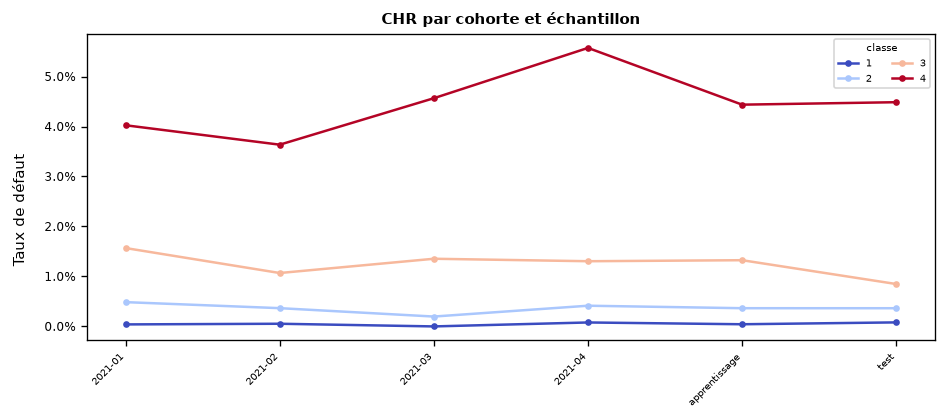

In [11]:
fig = plot_stabilite(pl.concat([detail_coh, detail_ech]).with_columns(variable=pl.lit("CHR par cohorte et échantillon")),
                     ["CHR par cohorte et échantillon"], n_cols=1, figsize_par_plot=(8, 3.6))
plt.show()

## 7.3 Homogénéité intra-CHR selon une variable exogène

Question : **dans une même CHR**, une information extérieure au score distingue-t-elle encore des dossiers de risque
différent ? On utilise des variables **non testées dans le modèle** (cours 7.3.1) : les variables rejetées au
stepwise ne sont pas pertinentes ici. Retenues, si présentes dans la base :

- l'**âge** : volontairement exclu du modèle pour raison réglementaire (2, § 2.5) — exemple cité par le cours ;
- le **nombre de titulaires** du compte joint, le **code marché** : variables de segmentation, hors du score.

Pour chaque CHR et chaque modalité (comparée au reste de la CHR) : **test de Welch** et **h de Cohen**. Une CHR n'est
jugée hétérogène que si l'écart est **à la fois** significatif (p < 5 %) et non négligeable (|h| ≥ 0,2), le test de
Welch étant très puissant sur de grands effectifs (7.3.2).

In [12]:
cles = [ID_COL, DATE_COL]
exo_dispo = [c for c in EXOGENES if c in pl.read_parquet_schema(BASE_ORI)]
print(f"Variables exogènes disponibles : {exo_dispo}")

exo = pl.read_parquet(BASE_ORI, columns=cles + exo_dispo)
assert exo.select(cles).is_duplicated().sum() == 0, "clé (gdt, date) non unique"
d_exo = df.select(cles + ["echantillon", "CHR", TARGET]).join(exo, on=cles, how="left")

app_exo = d_exo.filter(pl.col("echantillon") == "apprentissage")
# Variable quasi constante sur le segment (modalité majoritaire ≥ 99 %) : rien à tester
part_max = {v: app_exo[v].cast(pl.String).value_counts(normalize=True)["proportion"].max() for v in exo_dispo}
exo_dispo = [v for v in exo_dispo if part_max[v] < 0.99]
print(f"Variables testées (non quasi constantes) : {exo_dispo}")
# Variable numérique à plus de 2 valeurs : deux groupes autour de la médiane de l'apprentissage
for v in exo_dispo:
    if d_exo[v].dtype.is_numeric() and d_exo[v].n_unique() > 2:
        med = float(app_exo[v].median())
        d_exo = d_exo.with_columns(binariser_mediane(d_exo, v, med))

homog = pl.concat([homogeneite_exogene(d_exo.filter(pl.col("echantillon") == "apprentissage"), "CHR", TARGET, v,
                                       alpha=ALPHA) for v in exo_dispo])
with pl.Config(tbl_rows=-1, fmt_str_lengths=40):
    display(homog)

Variables exogènes disponibles : ['age', 'age_ans', 'nb_tiers', 'code_marche_v2', 'type_PM_PP']
Variables testées (non quasi constantes) : ['age', 'age_ans', 'nb_tiers']


variable,CHR,modalite,n_a,n_b,taux_a,taux_b,t,pvalue,h,taille_effet,conclusion
str,i64,str,i64,i64,f64,f64,f64,f64,f64,str,str
"""age""",1,"""18-25""",91,29973,0.0,0.000434,null,null,null,null,"""effectif insuffisant"""
"""age""",1,"""25-40""",3704,26360,0.00027,0.000455,-0.617075,0.53721,-0.009812,"""négligeable""","""homogène"""
"""age""",1,"""40-60""",10380,19684,0.000385,0.000457,-0.292599,0.769831,-0.003505,"""négligeable""","""homogène"""
"""age""",1,"""60+""",15889,14175,0.000503,0.000353,0.633982,0.526097,0.007316,"""négligeable""","""homogène"""
"""age""",2,"""18-25""",65,9816,0.0,0.003667,null,null,null,null,"""effectif insuffisant"""
"""age""",2,"""25-40""",2389,7492,0.004604,0.003337,0.824685,0.409606,0.02022,"""négligeable""","""homogène"""
"""age""",2,"""40-60""",4681,5200,0.002991,0.004231,-1.030729,0.302693,-0.020749,"""négligeable""","""homogène"""
"""age""",2,"""60+""",2746,7135,0.004006,0.003504,0.360182,0.718728,0.008212,"""négligeable""","""homogène"""
"""age""",3,"""18-25""",43,4486,0.0,0.013375,null,null,null,null,"""effectif insuffisant"""


In [13]:
homog.group_by("variable", "conclusion").len().sort("variable", "conclusion")

variable,conclusion,len
str,str,u32
"""age""","""effectif insuffisant""",4
"""age""","""homogène""",11
"""age""","""écart significatif mais néglig…",1
"""age_ans""","""homogène""",3
"""age_ans""","""écart significatif mais néglig…",1
"""nb_tiers""","""effectif insuffisant""",2
"""nb_tiers""","""homogène""",1
"""nb_tiers""","""écart significatif mais néglig…",1


## 7.4 Hétérogénéité inter-CHR

Deux CHR adjacentes doivent avoir des niveaux de risque suffisamment différents : $R_k \geq 30\,\%$ et, pour aller plus
loin, la borne basse de l'IC de $R_k$ ≥ 30 %. Le cours rappelle que c'est une **décision métier** : deux CHR à 25 %
d'écart qui ne se croisent jamais peuvent être conservées. Contrôle sur l'apprentissage et sur le test.

In [14]:
pl.concat([
    tab_app.select(pl.lit("apprentissage").alias("echantillon"), "CHR", "n_defaut", "taux_defaut", "R", "R_ic_bas",
                   "R_ic_haut", "ecart_ok", "ecart_ic_ok"),
    tab_test.select(pl.lit("test").alias("echantillon"), "CHR", "n_defaut", "taux_defaut", "R", "R_ic_bas",
                    "R_ic_haut", "ecart_ok", "ecart_ic_ok"),
]).filter(pl.col("R").is_not_null())

echantillon,CHR,n_defaut,taux_defaut,R,R_ic_bas,R_ic_haut,ecart_ok,ecart_ic_ok
str,i64,f64,f64,f64,f64,f64,bool,bool
"""apprentissage""",2,36.0,0.003643,7.425681,2.085584,12.765778,true,true
"""apprentissage""",3,60.0,0.013248,2.636196,1.139185,4.133208,true,true
"""apprentissage""",4,119.0,0.04437,2.349186,1.322209,3.376163,true,true
"""test""",2,9.0,0.003639,3.51759,-1.144516,8.179696,true,false
"""test""",3,10.0,0.008482,1.3306,-0.761966,3.423167,true,false
"""test""",4,31.0,0.044863,4.289291,0.552017,8.026565,true,true


## 7.5 Échelle maître

Une échelle maître harmonise les CHR de **plusieurs modèles** (CHR d'usage contre CHR techniques). À ce stade, seul
le segment des comptes joints est modélisé : il n'y a qu'un système de notation, l'échelle maître n'a pas d'objet.
Elle sera construite si les autres segments sont modélisés, de préférence **sur l'échelle des PD calibrées** (ch. 8),
seule grandeur comparable d'un modèle à l'autre (le numéro d'une CHR n'a de sens que dans son propre modèle).

## 7.6 Perte d'information induite par la mise en classe

Comparaison du score en points et des CHR : AUC, Gini, KS et AUC PR (pertinente pour un taux de défaut faible ; la
référence d'un modèle aléatoire est le taux de défaut). $\Delta Gini = Gini_{score} - Gini_{CHR}$. Une légère perte
est normale : le but n'est pas de maximiser le Gini des CHR mais de garder un compromis acceptable.

In [15]:
perte = pl.concat([perte_information(df_app[TARGET], df_app["points"], df_app["CHR"], "apprentissage"),
                   perte_information(df_test[TARGET], df_test["points"], df_test["CHR"], "test")])
perte.select("modele", "n", "n_defaut", "auc", "gini", "gini_ic_bas", "gini_ic_haut", "ks", "auc_pr", "taux_defaut", "delta_gini")

modele,n,n_defaut,auc,gini,gini_ic_bas,gini_ic_haut,ks,auc_pr,taux_defaut,delta_gini
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""score en points — apprentissag…",47156,228,0.891903,0.783806,0.728431,0.839182,0.651892,0.044178,0.004835,0.0
"""CHR — apprentissage""",47156,228,0.87986,0.759721,0.701943,0.817498,0.635241,0.031952,0.004835,0.024086
"""score en points — test""",11791,56,0.871935,0.743871,0.62433,0.863411,0.631161,0.070822,0.004749,0.0
"""CHR — test""",11791,56,0.850405,0.70081,0.574058,0.827561,0.576284,0.031109,0.004749,0.043061


## Comparaison : CHR construites avec optbinning

La librairie **optbinning** (`OptimalBinning`) découpe le score par un pré-découpage en arbre (20 classes) puis une
optimisation sous contraintes qui maximise l'IV. On lui impose les mêmes contraintes que ci-dessus : taux de défaut
décroissant avec les points, au moins 2 % des dossiers et 5 défauts par classe. Elle n'a pas de règle d'écart relatif
de 30 % : celle-ci est contrôlée après coup. Trois variantes :

- **optbinning libre** : nombre de classes choisi par l'optimisation ;
- **optbinning, 20 défauts min.** : contrainte d'effectif plus forte ;
- **optbinning, 4 classes max.** : même nombre de CHR que le découpage retenu.

Toutes sont évaluées avec les critères du chapitre (7.2, 7.4, 7.6) et comparées aux deux découpages de la section 7.1.

In [16]:
DECOUPAGES = {
    "retenu (IC de R ≥ 30 %)": resultats["ic"][0],
    "30 % ponctuel": resultats["ponctuel"][0],
    "optbinning libre": chr_optbinning(df_app["points"], df_app[TARGET], min_bin_size=MIN_PART, min_bin_n_event=MIN_DEFAUTS),
    "optbinning, 20 défauts min.": chr_optbinning(df_app["points"], df_app[TARGET], min_bin_size=MIN_PART, min_bin_n_event=20),
    "optbinning, 4 classes max.": chr_optbinning(df_app["points"], df_app[TARGET], min_bin_size=MIN_PART,
                                                 min_bin_n_event=MIN_DEFAUTS, max_n_bins=4),
}
comparaison = comparer_decoupages(df_app, df_test, DECOUPAGES, TARGET, seuil=SEUIL, alpha=ALPHA)
with pl.Config(tbl_cols=-1, fmt_str_lengths=90, tbl_width_chars=250):
    display(comparaison)

decoupage,n_chr,bornes,parts_app,defauts_app,taux_app,ecart_30_app,ic_30_app,ordre_test,cohortes_ordonnees,gini_chr_app,gini_chr_test,delta_gini_test
str,i64,str,str,str,str,bool,bool,bool,f64,f64,f64,f64
"""retenu (IC de R ≥ 30 %)""",4,"""594 · 632 · 671""","""63.8% · 21.0% · 9.6% · 5.7%""","""13 · 36 · 60 · 119""","""0.04% · 0.36% · 1.32% · 4.44%""",true,true,true,1.0,0.759721,0.70081,0.043061
"""30 % ponctuel""",6,"""594 · 615 · 632 · 641 · 671""","""63.8% · 16.0% · 4.9% · 5.3% · 4.3% · 5.7%""","""13 · 21 · 15 · 29 · 31 · 119""","""0.04% · 0.28% · 0.65% · 1.17% · 1.52% · 4.44%""",true,false,false,0.25,0.767435,0.708763,0.035107
"""optbinning libre""",6,"""594 · 619 · 636 · 647 · 676""","""62.6% · 14.3% · 5.3% · 5.1% · 7.0% · 5.7%""","""12 · 17 · 11 · 19 · 50 · 119""","""0.04% · 0.25% · 0.44% · 0.79% · 1.51% · 4.44%""",true,false,false,0.5,0.771205,0.70831,0.035561
"""optbinning, 20 défauts min.""",4,"""594 · 619 · 647""","""76.9% · 10.3% · 7.0% · 5.7%""","""29 · 30 · 50 · 119""","""0.08% · 0.62% · 1.51% · 4.44%""",true,true,true,1.0,0.729879,0.675886,0.067985
"""optbinning, 4 classes max.""",4,"""594 · 636 · 676""","""62.6% · 19.6% · 12.1% · 5.7%""","""12 · 28 · 69 · 119""","""0.04% · 0.30% · 1.21% · 4.44%""",true,true,true,1.0,0.762939,0.707176,0.036694


In [17]:
for nom in [n for n in DECOUPAGES if n.startswith("optbinning")]:
    b = DECOUPAGES[nom]
    t = table_chr(df_test.with_columns(CHR=pl.Series(affecter_chr(df_test["points"], b))), "CHR", TARGET, SEUIL, ALPHA)
    a = table_chr(df_app.with_columns(CHR=pl.Series(affecter_chr(df_app["points"], b))), "CHR", TARGET, SEUIL, ALPHA)
    print(f"=== {nom} : {len(b) + 1} CHR, bornes {b}")
    display(a.select("CHR", "n", "part", "n_defaut", "taux_defaut", "R", "R_ic_bas", "ecart_ok", "ecart_ic_ok")
             .join(t.select("CHR", n_defaut_test="n_defaut", taux_test="taux_defaut"), on="CHR", how="left"))

=== optbinning libre : 6 CHR, bornes [594.0, 619.0, 636.0, 647.0, 676.0]


CHR,n,part,n_defaut,taux_defaut,R,R_ic_bas,ecart_ok,ecart_ic_ok,n_defaut_test,taux_test
i64,u32,f64,f64,f64,f64,f64,bool,bool,f64,f64
1,29543,0.626495,12.0,0.000406,null,null,null,null,6.0,0.000819
2,6742,0.142972,17.0,0.002522,5.20774,0.623292,true,true,4.0,0.002384
3,2481,0.052613,11.0,0.004434,0.758352,-0.572749,true,false,2.0,0.003145
4,2390,0.050683,19.0,0.00795,0.793039,-0.534597,true,false,5.0,0.008993
5,3318,0.070362,50.0,0.015069,0.895562,-0.100729,true,false,8.0,0.008859
6,2682,0.056875,119.0,0.04437,1.944385,0.983413,true,true,31.0,0.044863


=== optbinning, 20 défauts min. : 4 CHR, bornes [594.0, 619.0, 647.0]


CHR,n,part,n_defaut,taux_defaut,R,R_ic_bas,ecart_ok,ecart_ic_ok,n_defaut_test,taux_test
i64,u32,f64,f64,f64,f64,f64,bool,bool,f64,f64
1,36285,0.769467,29.0,0.000799,null,null,null,null,10.0,0.00111
2,4871,0.103295,30.0,0.006159,6.706058,2.77961,true,true,7.0,0.005872
3,3318,0.070362,50.0,0.015069,1.446755,0.344543,true,true,8.0,0.008859
4,2682,0.056875,119.0,0.04437,1.944385,0.983413,true,true,31.0,0.044863


=== optbinning, 4 classes max. : 4 CHR, bornes [594.0, 636.0, 676.0]


CHR,n,part,n_defaut,taux_defaut,R,R_ic_bas,ecart_ok,ecart_ic_ok,n_defaut_test,taux_test
i64,u32,f64,f64,f64,f64,f64,bool,bool,f64,f64
1,29543,0.626495,12.0,0.000406,null,null,null,null,6.0,0.000819
2,9223,0.195585,28.0,0.003036,6.474105,1.422749,true,true,6.0,0.002593
3,5708,0.121045,69.0,0.012088,2.981799,1.238067,true,true,13.0,0.00891
4,2682,0.056875,119.0,0.04437,2.670482,1.595029,true,true,31.0,0.044863


**Lecture** (version de référence) : comme en v2, optbinning libre donne 6 CHR qui ne passent pas l'IC des 30 % ni
l'ordre sur le test ; **optbinning à 4 classes** (> 676 · 637 – 676 · 595 – 636 · ≤ 594 points) passe tous les critères,
avec un Gini de test de 70,7 % contre 70,1 % pour le découpage retenu : écart faible ici.

## Export

In [18]:
SORTIE.parent.mkdir(parents=True, exist_ok=True)
SORTIE.write_text(json.dumps({
    "grille": GRILLE.name, "critere": CRITERE, "seuil": SEUIL,
    "bornes_points": BORNES, "libelles": {str(k): v for k, v in LIBELLES.items()},
    "convention": "CHR 1 = la moins risquée ; points ]b(j-1) ; b(j)]",
}, ensure_ascii=False, indent=1), encoding="utf-8")
def sans_nan(t):   # Excel n'accepte ni NaN ni infini
    return t.with_columns(pl.when(pl.col(pl.Float64).is_finite()).then(pl.col(pl.Float64)).otherwise(None))

exporter_excel({k: sans_nan(v) for k, v in {
    "chr_apprentissage": tab_app, "chr_test": tab_test, "journal_fusions": JOURNAL, "stabilite_cohortes": detail_coh,
    "homogeneite": homog, "perte_information": perte, "comparaison_optbinning": comparaison}.items()}, SORTIE_XLS)
print(f"CHR : {SORTIE}\nTables : {SORTIE_XLS}")

CHR : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\chr\chr_joint.json
Tables : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\chr\chr_joint.xlsx


## Synthèse des décisions (version de référence, modèle à 5 variables)

Même démarche et même critère que `7 - CHR_joint_v2` (commentaires détaillés dans ce notebook) :

| § | Résultat |
|---|----------|
| 7.1 / 7.4 | **4 CHR** : > 671 · 633 – 671 · 595 – 632 · ≤ 594 points ; parts 63,8 % · 21,0 % · 9,6 % · 5,7 % ; taux de défaut 0,04 % · 0,36 % · 1,32 % · 4,44 % |
| 7.2 | ordre respecté dans 100 % des cohortes et sur le test ; PSI max 0,0003 |
| 7.3 | âge et nombre de titulaires : aucun écart non négligeable |
| 7.6 | Gini apprentissage 78,4 % → 76,0 % ; Gini test 74,4 % → 70,1 % |

> La variante v2 garde un meilleur Gini après mise en classe (74,5 % contre 70,1 % en test).